# Лабораторная работа 4. Интеграция ML-моделей в production

**Вариант 6**

Оценка риска повторной госпитализации при выписке. Общие признаки в Feast, обучение и версии в MLflow, выдача прогноза и его объяснения в FastAPI. В последней части — прогноз сенсора NAB.

Установите `requirements.txt` в среде ядра. CSV можно указать через `LAB4_HOSPITAL` и `LAB4_SENSOR`. По умолчанию скрипты загружают открытые наборы.

In [1]:
import os
from pathlib import Path
from uuid import uuid4

import pandas as pd
from IPython.display import Image, display

from run import run_hospital
from sensor import run_sensor

work = Path("tmp") / f"notebook-{uuid4().hex[:8]}"
work.mkdir(parents=True)

## 1. Прототипы, Feast и версии

Пайплайн сравнивает три модели, строит offline и online признаки, регистрирует batch и online версии. Порог уведомлений подбирается на валидации, итоговые метрики рассчитываются на отложенном тесте.

Materializing 1 feature views from 2023-12-31 23:00:00+00:00 to 2024-01-01 02:00:00+00:00 into the sqlite online store.

discharge_v1:


## METRICS ##
FEATURE_MATCH_TEST_PASSED=True
DATA_DRIFT_SCORE=0.0136
INFERENCE_LATENCY_MS=5.59
ONLINE_BATCH_DIFFERENCE=-0.0013
UNIQUE_REQUIREMENT_IMPACT=2.1200


,auc,ap,recall,fpr
Логистическая регрессия,0.551302,0.149116,0.010884,0.006648
Случайный лес,0.559392,0.149633,0.009524,0.006648
Градиентный бустинг,0.550437,0.146714,0.006803,0.006648


{'checked': 256, 'max_abs_diff': 0.0, 'passed': True}

{'batch': '1', 'online': '2'}

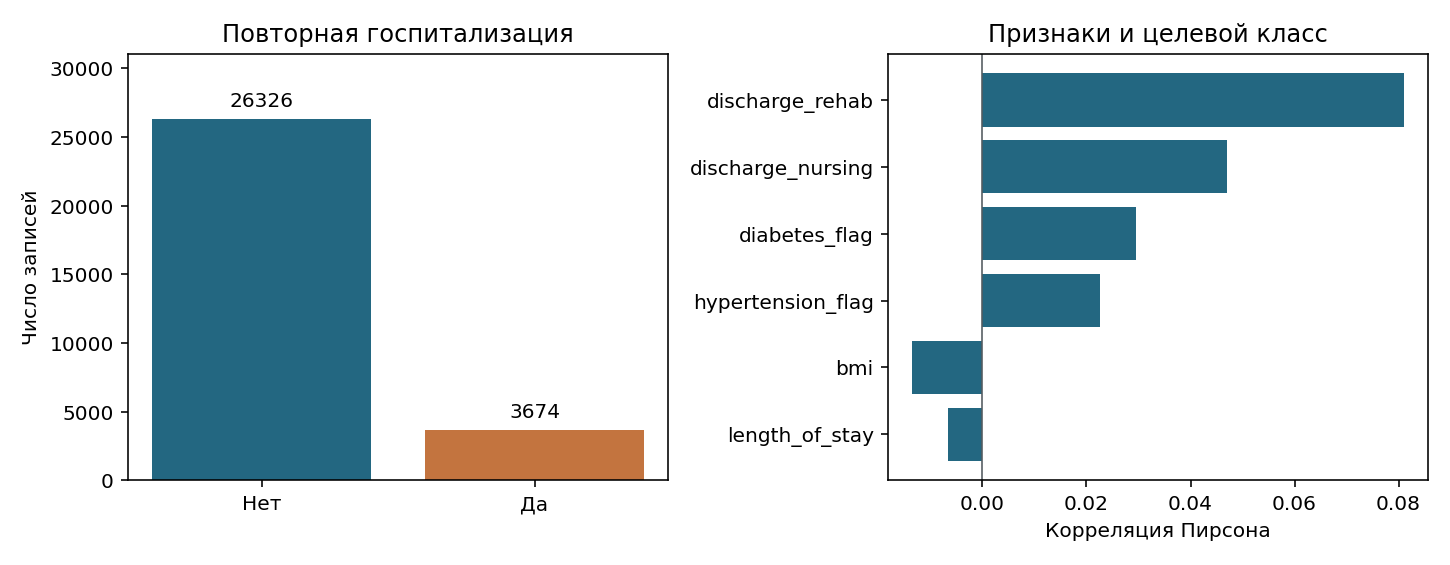

In [2]:
hospital = run_hospital(os.getenv("LAB4_HOSPITAL"), work)
display(pd.DataFrame(hospital["models_validation"]).T[["auc", "ap", "recall", "fpr"]])
display(hospital["feature_match"], hospital["versions"])
display(Image(filename=str(work / "eda.png")))

Feast отдаёт одну версию признаков для обучения и API. Даты выгрузки заменены фиксированной точкой симуляции, метка и идентификатор в модель не передаются.

## 2. API, SHAP и мониторинг

В HTTP-проверке измеряются задержки, проверяются ошибки входа, shadow и canary с откатом. SHAP объясняет вклад в логит. Для дрейфа сравниваются контрольное и изменённое окна.

In [3]:
display(pd.DataFrame({k: hospital["serving"][k] for k in ("baseline", "explanation", "candidate")}).T)
display(hospital["serving"]["canary"]["traffic_by_version"])
display(pd.Series(hospital["interpretation"]["example_shap"], name="Вклад в логит"))
display(pd.DataFrame({k: {m: hospital["monitoring"][k][m] for m in
                         ("max_psi", "accuracy_drop", "retrain")} for k in ("healthy", "injected")}).T)

,requests,p50_ms,p95_ms,p99_ms,throughput_rps,errors,errors_per_sec
baseline,240.0,5.05065,5.59384,6.032471,195.016943,0.0,0.0
explanation,240.0,6.18460,7.71380,8.568307,155.663425,0.0,0.0
candidate,NaN,NaN,5.87808,NaN,189.000189,0.0,NaN


{'1': 229, '2': 11}

age                  0.025697
bmi                  0.022070
systolic             0.003717
diastolic            0.015732
cholesterol          0.003139
medication_count    -0.006254
length_of_stay       0.022677
diabetes_flag        0.089424
hypertension_flag    0.094995
discharge_rehab     -0.148811
discharge_nursing   -0.059761
Name: Вклад в логит, dtype: float64

,max_psi,accuracy_drop,retrain
healthy,0.013561,0.006667,False
injected,3.339593,0.232667,True


Пояснение не меняет вероятность и проверяется сложением вкладов. При сдвиге создаётся новая версия в реестре. Перевод кандидата под трафик проходит отдельную проверку.

## 3. Пакетное и онлайн-обучение

Сравниваются модели на одном тесте после 24 имитированных часовых обновлений. В поток поступают уже созревшие метки.

,auc,ap,accuracy,f1,recall,fpr
batch,0.576584,0.158786,0.871333,0.017812,0.009524,0.008357
online,0.575285,0.157118,0.872000,0.007752,0.004082,0.006838


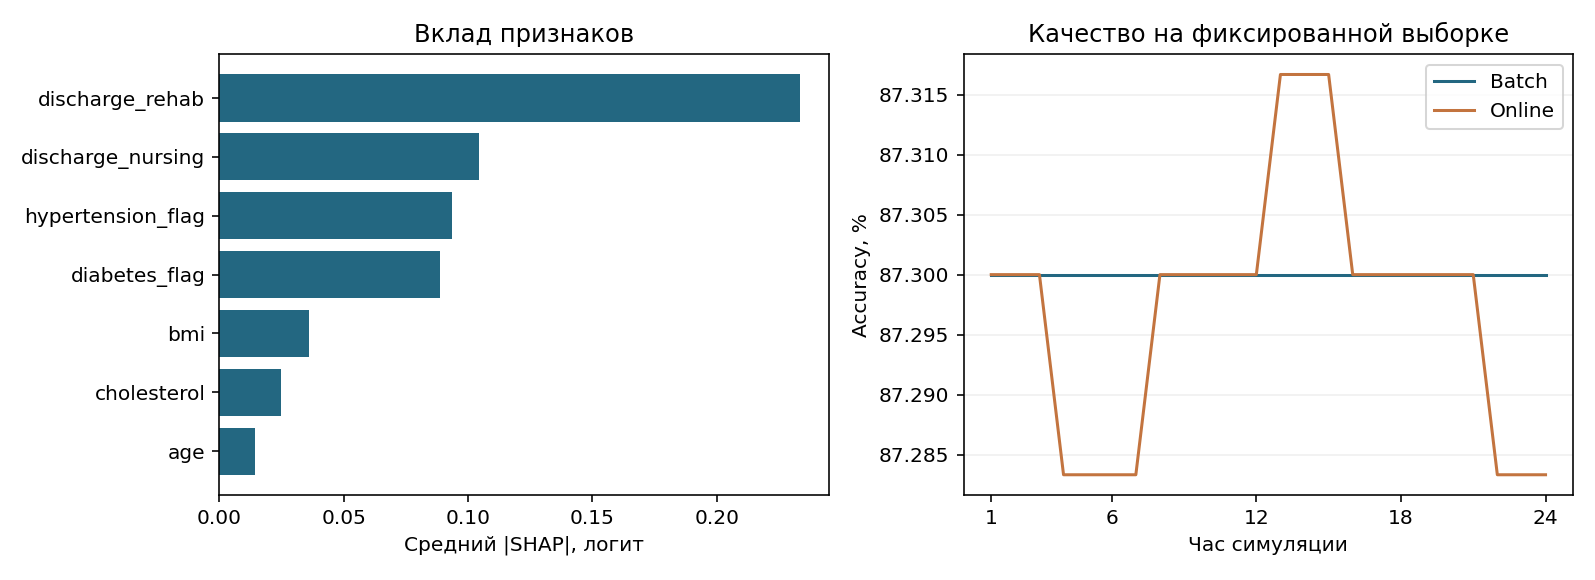

In [4]:
display(pd.DataFrame(hospital["final_test"]).T)
display(Image(filename=str(work / "learning.png")))

Решение о выборе стратегии учитывает ROC AUC, задержку, время обучения и дополнительные расходы на обработку потока меток.

## 4. NAB и автоотключение

Сравниваются прямой и рекурсивный прогнозы до 12 часов. Первая авария используется для выбора порога, вторая проверяется с фиксированными параметрами. Уведомление, сброс нагрузки и отключение записываются в журнал симуляции.

,notifications,true_notifications,false_notifications,precision,recall,lead_hours,false_per_day,missed_incidents,false_shutdowns
калибровка,6.0,4.0,2.0,0.666667,1.0,1.0,0.032809,0.0,1.0
тест,0.0,0.0,0.0,NaN,0.0,NaN,0.000000,1.0,0.0


,step,mae,mase,pinball_p90,n
direct,12.0,2.244933,1.284993,0.429619,1898.0
recursive,12.0,2.237290,1.280618,0.520603,1898.0


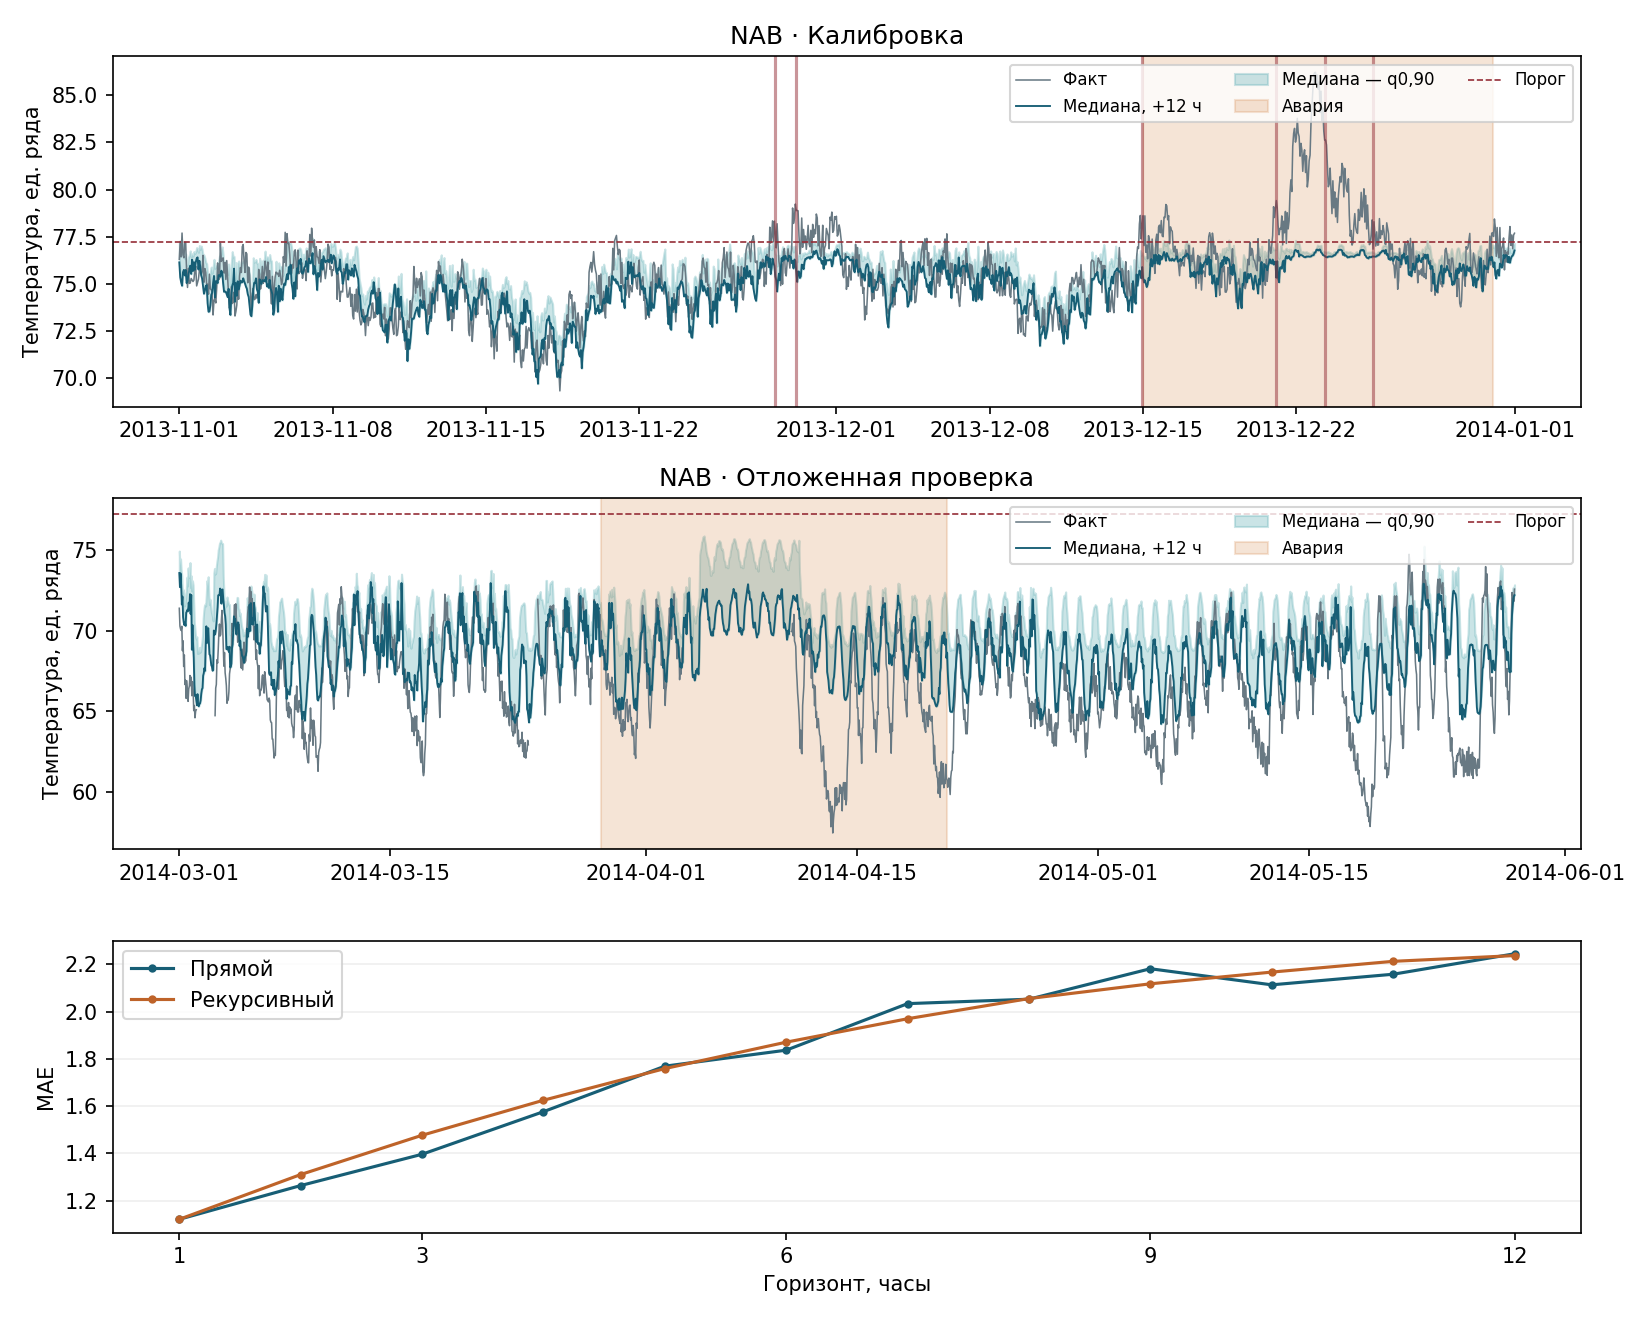

In [5]:
sensor = run_sensor(os.getenv("LAB4_SENSOR"), work)
display(pd.DataFrame({"калибровка": sensor["calibration"], "тест": sensor["test"]}).T)
display(pd.DataFrame({k: sensor["forecast"][k][-1] for k in ("direct", "recursive")}).T)
display(Image(filename=str(work / "sensor.png")))

На финальном окне оценивается не только точность прогноза температуры, но и способность заметить отложенную аварию. Сводка и ограничения описаны в [отчёте](report.md).